In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
from imblearn.over_sampling import SMOTE 
import warnings
warnings.filterwarnings('ignore')


In [2]:
df = pd.read_csv('UCI_Credit_Card.csv', index_col=0)

In [3]:
print(df.head())

    LIMIT_BAL  SEX  EDUCATION  MARRIAGE  AGE  PAY_0  PAY_2  PAY_3  PAY_4  \
ID                                                                         
1     20000.0    2          2         1   24      2      2     -1     -1   
2    120000.0    2          2         2   26     -1      2      0      0   
3     90000.0    2          2         2   34      0      0      0      0   
4     50000.0    2          2         1   37      0      0      0      0   
5     50000.0    1          2         1   57     -1      0     -1      0   

    PAY_5  ...  BILL_AMT4  BILL_AMT5  BILL_AMT6  PAY_AMT1  PAY_AMT2  PAY_AMT3  \
ID         ...                                                                  
1      -2  ...        0.0        0.0        0.0       0.0     689.0       0.0   
2       0  ...     3272.0     3455.0     3261.0       0.0    1000.0    1000.0   
3       0  ...    14331.0    14948.0    15549.0    1518.0    1500.0    1000.0   
4       0  ...    28314.0    28959.0    29547.0    2000.0    2

In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 30000 entries, 1 to 30000
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   LIMIT_BAL                   30000 non-null  float64
 1   SEX                         30000 non-null  int64  
 2   EDUCATION                   30000 non-null  int64  
 3   MARRIAGE                    30000 non-null  int64  
 4   AGE                         30000 non-null  int64  
 5   PAY_0                       30000 non-null  int64  
 6   PAY_2                       30000 non-null  int64  
 7   PAY_3                       30000 non-null  int64  
 8   PAY_4                       30000 non-null  int64  
 9   PAY_5                       30000 non-null  int64  
 10  PAY_6                       30000 non-null  int64  
 11  BILL_AMT1                   30000 non-null  float64
 12  BILL_AMT2                   30000 non-null  float64
 13  BILL_AMT3                   30000 no

In [5]:
print(df.isnull().sum())

LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default.payment.next.month    0
dtype: int64


#  ДОБАВЛЕНИЕ НОВЫХ ПРИЗНАКОВ (Feature Engineering)

In [6]:
df['PAY_MEAN'] = df[['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']].mean(axis=1)
bill_cols = ['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']
pay_cols  = ['PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
df['PAYMENT_RATIO'] = df[pay_cols].sum(axis=1) / (df[bill_cols].sum(axis=1) + 1)

# Проверка распределения целевой переменной

In [7]:
target_counts = df['default.payment.next.month'].value_counts()
print(f"Всего клиентов: {len(df)}")
print(f"Без дефолта (0): {target_counts[0]} ({target_counts[0]/len(df)*100:.2f}%)")
print(f"С дефолтом (1): {target_counts[1]} ({target_counts[1]/len(df)*100:.2f}%)")

Всего клиентов: 30000
Без дефолта (0): 23364 (77.88%)
С дефолтом (1): 6636 (22.12%)


# Подготовка данных для модели

In [8]:
X = df.drop('default.payment.next.month', axis=1)
y = df['default.payment.next.month']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Масштабирование данных

In [9]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# БАЛАНСИРОВКА КЛАССОВ 

In [10]:
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

# МОДЕЛЬ 1: Логистическая регрессия

In [11]:
log_reg = LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced')
log_reg.fit(X_train_scaled, y_train)

y_pred_lr = log_reg.predict(X_test_scaled)
y_pred_proba_lr = log_reg.predict_proba(X_test_scaled)[:, 1]

print(f"Точность (Accuracy): {log_reg.score(X_test_scaled, y_test):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba_lr):.4f}")
print("\nОтчёт по классификации:")
print(classification_report(y_test, y_pred_lr))

Точность (Accuracy): 0.6805
ROC-AUC: 0.7161

Отчёт по классификации:
              precision    recall  f1-score   support

           0       0.87      0.69      0.77      5841
           1       0.37      0.63      0.47      1659

    accuracy                           0.68      7500
   macro avg       0.62      0.66      0.62      7500
weighted avg       0.76      0.68      0.70      7500



# МОДЕЛЬ 2: Random Forest

In [12]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=10,
    class_weight='balanced',
    min_samples_leaf=5
)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_pred_proba_rf = rf_model.predict_proba(X_test)[:, 1]

print(f"Точность (Accuracy): {rf_model.score(X_test, y_test):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba_rf):.4f}")
print("\nОтчёт по классификации:")
print(classification_report(y_test, y_pred_rf))

Точность (Accuracy): 0.7832
ROC-AUC: 0.7756

Отчёт по классификации:
              precision    recall  f1-score   support

           0       0.87      0.84      0.86      5841
           1       0.51      0.58      0.54      1659

    accuracy                           0.78      7500
   macro avg       0.69      0.71      0.70      7500
weighted avg       0.79      0.78      0.79      7500



# КРОСС-ВАЛИДАЦИЯ 

In [13]:
cv_scores = cross_val_score(rf_model, X_train, y_train, cv=5, scoring='roc_auc')
print(f"\nCross-validation ROC-AUC (Random Forest): {cv_scores.mean():.4f} (+/- {cv_scores.std()*2:.4f})")



Cross-validation ROC-AUC (Random Forest): 0.7803 (+/- 0.0047)


# Важность признаков

In [14]:
feature_importance = pd.DataFrame({
    'Признак': X.columns,
    'Важность': rf_model.feature_importances_
}).sort_values('Важность', ascending=False).head(10)
print("\nТоп-10 важных признаков:")
print(feature_importance.to_string(index=False))


Топ-10 важных признаков:
      Признак  Важность
     PAY_MEAN  0.168937
        PAY_0  0.157351
        PAY_2  0.080276
        PAY_3  0.054006
PAYMENT_RATIO  0.043127
    BILL_AMT1  0.038524
     PAY_AMT2  0.038463
    LIMIT_BAL  0.037560
     PAY_AMT1  0.035609
     PAY_AMT3  0.033462


# Визуализация результатов

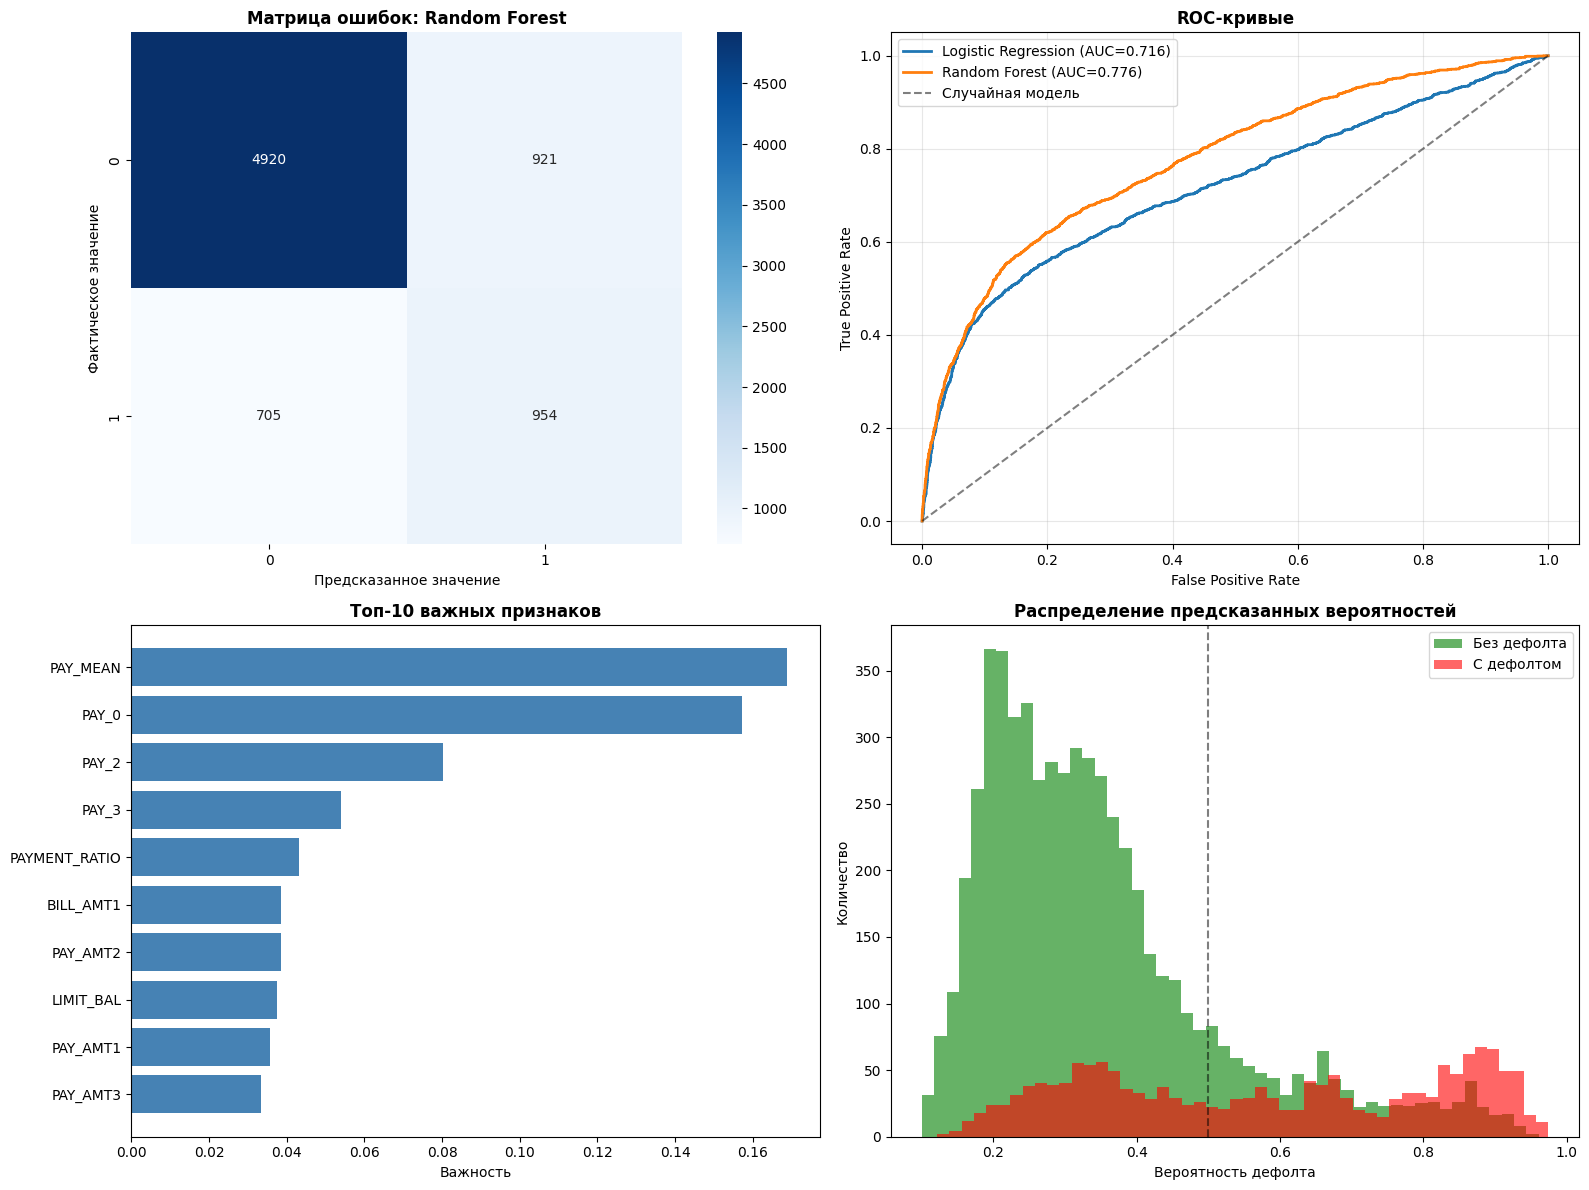


График сохранён как 'credit_default_analysis.png'


In [15]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', ax=axes[0, 0])
axes[0, 0].set_title('Матрица ошибок: Random Forest', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Фактическое значение')
axes[0, 0].set_xlabel('Предсказанное значение')

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_pred_proba_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_proba_rf)
axes[0, 1].plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC={roc_auc_score(y_test, y_pred_proba_lr):.3f})', linewidth=2)
axes[0, 1].plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC={roc_auc_score(y_test, y_pred_proba_rf):.3f})', linewidth=2)
axes[0, 1].plot([0, 1], [0, 1], 'k--', label='Случайная модель', alpha=0.5)
axes[0, 1].set_xlabel('False Positive Rate')
axes[0, 1].set_ylabel('True Positive Rate')
axes[0, 1].set_title('ROC-кривые', fontsize=12, fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

top_features = feature_importance.head(10)
axes[1, 0].barh(top_features['Признак'], top_features['Важность'], color='steelblue')
axes[1, 0].set_xlabel('Важность')
axes[1, 0].set_title('Топ-10 важных признаков', fontsize=12, fontweight='bold')
axes[1, 0].invert_yaxis()

axes[1, 1].hist(y_pred_proba_rf[y_test == 0], bins=50, alpha=0.6, label='Без дефолта', color='green')
axes[1, 1].hist(y_pred_proba_rf[y_test == 1], bins=50, alpha=0.6, label='С дефолтом', color='red')
axes[1, 1].set_xlabel('Вероятность дефолта')
axes[1, 1].set_ylabel('Количество')
axes[1, 1].set_title('Распределение предсказанных вероятностей', fontsize=12, fontweight='bold')
axes[1, 1].legend()
axes[1, 1].axvline(x=0.5, color='black', linestyle='--', label='Порог', alpha=0.5)

plt.tight_layout()
plt.savefig('credit_default_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nГрафик сохранён как 'credit_default_analysis.png'")


# Функция для предсказания нового клиента

In [16]:
def predict_default_probability(client_data_dict):
    client_df = pd.DataFrame([client_data_dict])
    

    client_df['PAY_MEAN'] = client_df[['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']].mean(axis=1)
    client_df['PAYMENT_RATIO'] = client_df[pay_cols].sum(axis=1) / (client_df[bill_cols].sum(axis=1) + 1)
    

    client_scaled = scaler.transform(client_df)
    prob_lr = log_reg.predict_proba(client_scaled)[0, 1]
    prob_rf = rf_model.predict_proba(client_df)[0, 1]
    
    print(f"\nВероятность дефолта:")
    print(f"  Logistic Regression: {prob_lr*100:.2f}%")
    print(f"  Random Forest: {prob_rf*100:.2f}%")
    print(f"  Средняя вероятность: {(prob_lr + prob_rf)/2*100:.2f}%")
    
    avg_prob = (prob_lr + prob_rf) / 2
    if avg_prob < 0.3:
        decision = "НИЗКИЙ РИСК - рекомендуется одобрить"
    elif avg_prob < 0.6:
        decision = "СРЕДНИЙ РИСК - требуется дополнительная проверка"
    else:
        decision = "ВЫСОКИЙ РИСК - рекомендуется отказать"
    
    print(f"\nРекомендация: {decision}")
    return prob_lr, prob_rf


# Пример использования

In [17]:
example_client = {
    'LIMIT_BAL': 50000.0,
    'SEX': 1,
    'EDUCATION': 2,
    'MARRIAGE': 1,
    'AGE': 35,
    'PAY_0': 0,
    'PAY_2': 0,
    'PAY_3': 0,
    'PAY_4': 0,
    'PAY_5': 0,
    'PAY_6': 0,
    'BILL_AMT1': 10000.0,
    'BILL_AMT2': 9000.0,
    'BILL_AMT3': 8000.0,
    'BILL_AMT4': 7000.0,
    'BILL_AMT5': 6000.0,
    'BILL_AMT6': 5000.0,
    'PAY_AMT1': 2000.0,
    'PAY_AMT2': 2000.0,
    'PAY_AMT3': 2000.0,
    'PAY_AMT4': 2000.0,
    'PAY_AMT5': 2000.0,
    'PAY_AMT6': 2000.0
}

predict_default_probability(example_client)


Вероятность дефолта:
  Logistic Regression: 56.17%
  Random Forest: 33.27%
  Средняя вероятность: 44.72%

Рекомендация: СРЕДНИЙ РИСК - требуется дополнительная проверка


(np.float64(0.5617137709480922), np.float64(0.332654717986564))